# H2: Does more data help?

**Claim refuted (B).** The mock paper trains quadratic logistic regression on 25%, 50% and 100% of each training
split, sees at most 3 points of improvement, and concludes that the difficulty is intrinsic.

**Hypothesis H2.** More data helps whenever the model can represent the signal.

* Independent variable: training-set size (5%, 10%, 25%, 50% and 100% of the training split) $\times$ model
  (quadratic LR, MLP on sign inputs).
* Dependent variable: test accuracy.
* Controls: 5 seeds; within a seed the validation and test splits stay fixed and only the training set shrinks
  (smaller sets are subsets of larger ones); LR is trained to convergence; hyper-parameters are the ones H1 chose.
* Decision rule (fixed in advance, on the paper's fractions): reject the paper's claim if the MLP gains more than
  $2\varepsilon$ from 25% to 100% while quadratic LR gains less than $\varepsilon$, with $\varepsilon$ the Chebyshev
  half-width on one test split ($\delta = 0.05$). The 5% and 10% points only show the shape of the curve.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures

from include.config import NS, SEEDS
from include.data import load, to_sign, split
from include.models import mlp, fit, accuracy
from include.stats import chebyshev_eps
from include.tracking import track, save_json, load_json
from include.figures import use_paper_style, savefig
from include.plots_h2 import plot_learning_curves

use_paper_style()
torch.set_num_threads(4)
FRACTIONS = (0.05, 0.1, 0.25, 0.5, 1.0)

h1 = load_json("H1_hparams.json")
assert h1 is not None, "run H1_learnability.ipynb first: H2 uses the hyper-parameters it chose"
chosen = {n: h1[str(n)] for n in NS}
print(chosen)


def quad_lr(X_tr, y_tr, X_te, y_te, C):
    poly = PolynomialFeatures(2, include_bias=False)
    clf = LogisticRegression(C=C, max_iter=5000).fit(poly.fit_transform(X_tr), y_tr)
    return clf.score(poly.transform(X_te), y_te)

{20: {'LogReg (d=1)': {'C': 0.01}, 'LogReg (d=2)': {'C': 0.01}, 'MLP (raw x)': {'width': 512, 'depth': 2, 'weight_decay': 0.1}, 'MLP (sign x)': {'width': 512, 'depth': 2, 'weight_decay': 0.1}}, 30: {'LogReg (d=1)': {'C': 0.01}, 'LogReg (d=2)': {'C': 0.1}, 'MLP (raw x)': {'width': 256, 'depth': 3, 'weight_decay': 0.01}, 'MLP (sign x)': {'width': 256, 'depth': 3, 'weight_decay': 0.01}}, 40: {'LogReg (d=1)': {'C': 0.1}, 'LogReg (d=2)': {'C': 10.0}, 'MLP (raw x)': {'width': 512, 'depth': 2, 'weight_decay': 0.1}, 'MLP (sign x)': {'width': 512, 'depth': 2, 'weight_decay': 0.1}}}


## 1. Learning curves

In [2]:
curves = {n: {"MLP": {f: [] for f in FRACTIONS}, "quad. LR": {f: [] for f in FRACTIONS}} for n in NS}
n_train, n_test = {}, {}
with track("H2_learning_curves"):
    for n in NS:
        X, y = load(n)
        cfg = chosen[n]["MLP (sign x)"]
        C = chosen[n]["LogReg (d=2)"]["C"]
        for seed in SEEDS:
            X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, seed)
            order = np.random.default_rng(seed).permutation(len(y_tr))
            for f in FRACTIONS:
                keep = order[:int(f * len(y_tr))]
                X_f, y_f = X_tr[keep], y_tr[keep]
                curves[n]["quad. LR"][f].append(quad_lr(X_f, y_f, X_te, y_te, C))
                torch.manual_seed(seed)
                model, _ = fit(mlp(n, cfg["width"], cfg["depth"]), to_sign(X_f), y_f, to_sign(X_va), y_va,
                               weight_decay=cfg["weight_decay"], seed=seed)
                curves[n]["MLP"][f].append(accuracy(model, to_sign(X_te), y_te))
            print(f"n={n} seed={seed}: MLP " + " ".join(f"{curves[n]['MLP'][f][-1]:.3f}" for f in FRACTIONS)
                  + " | quad. LR " + " ".join(f"{curves[n]['quad. LR'][f][-1]:.3f}" for f in FRACTIONS), flush=True)
        n_train[n], n_test[n] = len(y_tr), len(y_te)

n=20 seed=0: MLP 0.505 0.521 0.551 0.710 0.925 | quad. LR 0.510 0.513 0.505 0.526 0.532


n=20 seed=1: MLP 0.525 0.526 0.560 0.709 0.924 | quad. LR 0.525 0.527 0.525 0.522 0.549


n=20 seed=2: MLP 0.512 0.528 0.552 0.725 0.935 | quad. LR 0.514 0.520 0.545 0.546 0.539


n=20 seed=3: MLP 0.506 0.525 0.558 0.692 0.935 | quad. LR 0.528 0.524 0.513 0.534 0.533


n=20 seed=4: MLP 0.505 0.500 0.565 0.691 0.929 | quad. LR 0.499 0.503 0.522 0.539 0.552


n=30 seed=0: MLP 0.501 0.510 0.517 0.557 0.938 | quad. LR 0.500 0.515 0.503 0.505 0.517


... (6 outputs left out)

n=40 seed=2: MLP 0.505 0.509 0.515 0.599 0.946 | quad. LR 0.498 0.517 0.506 0.517 0.522


n=40 seed=3: MLP 0.505 0.505 0.528 0.590 0.951 | quad. LR 0.509 0.502 0.517 0.515 0.525


n=40 seed=4: MLP 0.498 0.506 0.517 0.693 0.951 | quad. LR 0.496 0.508 0.514 0.516 0.531


[H2_learning_curves] 23177s, ~289.71 Wh, ~35.92 gCO2e


## 2. Decision rule

In [3]:
summary = {}
for n in NS:
    eps = chebyshev_eps(n_test[n])
    gain = {m: float(np.mean(curves[n][m][1.0]) - np.mean(curves[n][m][0.25])) for m in ("MLP", "quad. LR")}
    supported = gain["MLP"] > 2 * eps and gain["quad. LR"] < eps
    summary[n] = {"eps": eps, "gain": gain, "H2_supported": bool(supported)}
    print(f"n={n} (eps {eps:.3f})")
    for m in ("MLP", "quad. LR"):
        print(f"    {m:<9} " + "  ".join(f"{f:>4.0%}: {np.mean(curves[n][m][f]):.3f}" for f in FRACTIONS)
              + f"   gain 25%->100%: {gain[m]:+.3f}")
    print(f"    MLP gain > 2 eps ({2 * eps:.3f}) and LR gain < eps ({eps:.3f}): {supported}\n")

save_json({"curves": {str(n): {m: {str(f): a for f, a in c.items()} for m, c in curves[n].items()} for n in NS},
           "n_train": {str(n): v for n, v in n_train.items()},
           "summary": {str(n): s for n, s in summary.items()}}, "H2_more_data.json")

n=20 (eps 0.046)
    MLP         5%: 0.511   10%: 0.520   25%: 0.557   50%: 0.705  100%: 0.930   gain 25%->100%: +0.372
    quad. LR    5%: 0.515   10%: 0.517   25%: 0.522   50%: 0.533  100%: 0.541   gain 25%->100%: +0.019
    MLP gain > 2 eps (0.091) and LR gain < eps (0.046): True

n=30 (eps 0.035)
    MLP         5%: 0.508   10%: 0.514   25%: 0.524   50%: 0.570  100%: 0.928   gain 25%->100%: +0.404
    quad. LR    5%: 0.506   10%: 0.515   25%: 0.515   50%: 0.521  100%: 0.530   gain 25%->100%: +0.015
    MLP gain > 2 eps (0.071) and LR gain < eps (0.035): True

n=40 (eps 0.028)
    MLP         5%: 0.507   10%: 0.510   25%: 0.523   50%: 0.620  100%: 0.948   gain 25%->100%: +0.425
    quad. LR    5%: 0.504   10%: 0.511   25%: 0.515   50%: 0.520  100%: 0.530   gain 25%->100%: +0.015
    MLP gain > 2 eps (0.056) and LR gain < eps (0.028): True



## 3. Figure

Mean test accuracy over 5 seeds ($\pm$ one standard deviation): MLP (solid) and quadratic LR (dashed). The dotted line
is the 90% target. (`report_figures.ipynb` redraws this from `results/H2_more_data.json` without retraining.)

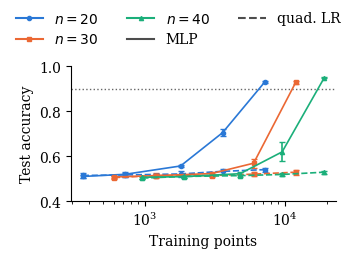

In [4]:
fig = plot_learning_curves(curves, FRACTIONS, n_train)
savefig(fig, "H2_learning_curves")
plt.show()